In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [53]:
df=pd.read_csv('titanic_toy.csv')

In [54]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [55]:
x=df.drop(columns=['Survived'])
y=df['Survived']

In [56]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [57]:
x_train['Age99']=x_train['Age'].fillna(99)
x_train['Age-minus1']=x_train['Age'].fillna(-1)

x_train['Fare999']=x_train['Fare'].fillna(999)
x_train['Fare_minus1']=x_train['Fare'].fillna(-1)

In [58]:
print("Original Age variable variance",x_train['Age'].var())
print("Age variable variance aftr mean imputation",x_train['Age99'].var())
print(" Age variable variance aftr median imputation",x_train['Age-minus1'].var())

print("Original Fare variable variance",x_train['Fare'].var())
print("Fare variable variance aftr mean imputation",x_train['Fare999'].var())
print("Fare variable variance aftr median imputation",x_train['Fare_minus1'].var())

Original Age variable variance 204.3495133904614
Age variable variance aftr mean imputation 951.7275570187172
 Age variable variance aftr median imputation 318.0896202624484
Original Fare variable variance 2448.197913706318
Fare variable variance aftr mean imputation 47219.20265217623
Fare variable variance aftr median imputation 2378.5676784883503


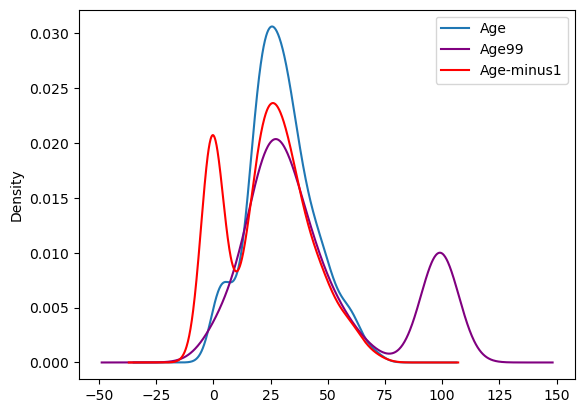

In [59]:
fig=plt.figure()
ax=fig.add_subplot(111)

# original age distribution
x_train["Age"].plot(kind='kde',ax=ax)

#distribution of variable imputed with the mean
x_train["Age99"].plot(kind='kde',ax=ax,color='purple')

#distribution of variable imputed with the median
x_train["Age-minus1"].plot(kind='kde',ax=ax,color='red')

#ads legends
lines,labels=ax.get_legend_handles_labels()
ax.legend(lines,labels,loc='best')

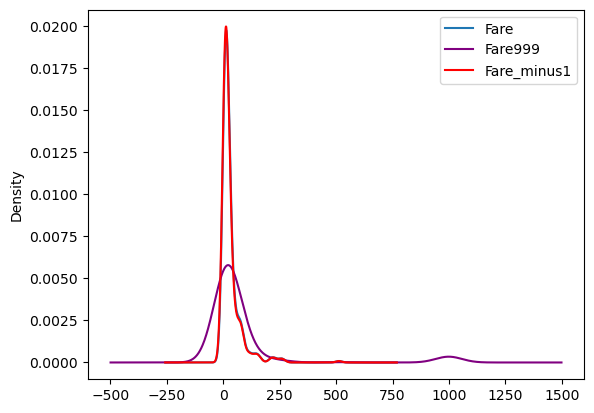

In [60]:
fig=plt.figure()
ax=fig.add_subplot(111)

# original age distribution
x_train["Fare"].plot(kind='kde',ax=ax)

#distribution of variable imputed with the mean
x_train["Fare999"].plot(kind='kde',ax=ax,color='purple')

#distribution of variable imputed with the median
x_train["Fare_minus1"].plot(kind='kde',ax=ax,color='red')

# # #ads legends
# # lines,labels=ax.get_legend_handles_labels()
# # ax.legend(lines,labels,loc='best')
ax.legend(loc='best')


## Using sklearn

In [61]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [62]:

imputer1=SimpleImputer(strategy='constant',fill_value=99)
imputer2=SimpleImputer(strategy ='constant',fill_value=999)

In [63]:
trf = ColumnTransformer([

    # Apply imputer1  on the "Age" column
    ('imputer1', imputer1, ['Age']),  

    # Apply imputer2  on the "Fare" column
    ('imputer2', imputer2, ['Fare'])  

], remainder='passthrough') 

In [64]:
trf.fit(x_train)
# 👉 imputer1 learns the fill value (e.g., median Age = 28).
# 👉 imputer2 learns the fill value (e.g., mean Fare = 32.2).

C:\Users\banik\anaconda3\Lib\site-packages\sklearn\compose\_column_transformer.py:1623: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('imputer1',
                                 SimpleImputer(fill_value=99,
                                               strategy='constant'),
                                 ['Age']),
                                ('imputer2',
                                 SimpleImputer(fill_value=999,
                                               strategy='constant'),
                                 ['Fare'])])

In [65]:
trf.named_transformers_['imputer1'].statistics_

array([99.])

In [66]:
x_train=trf.transform(x_train)
x_test=trf.transform(x_test)
# 👉 All missing "Age" values are replaced with 28.
# 👉 All missing "Fare" values are replaced with 32.2.
# 👉 Other columns stay the same.

In [67]:
x_train

array([[ 40.    ,  27.7208,   0.    ],
       [  4.    ,  16.7   ,   2.    ],
       [ 47.    ,   9.    ,   0.    ],
       ...,
       [ 71.    ,  49.5042,   0.    ],
       [ 99.    , 221.7792,   0.    ],
       [ 99.    ,  25.925 ,   0.    ]])